# Mini-Project 3 — Lake Victoria Fish Stock & Export Risk Model (Jinja cooperative)

Questions: **(a)** is the harvesting rate sustainable, **(b)** how risky is revenue?
Classes `FishStock`, `PriceModel` and `RiskAssessor` live in `src/fishery.py`. One time step = one week; stock in
tonnes; price in UGX/kg; revenue in UGX.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
DATA = ROOT / "data"; DATA.mkdir(exist_ok=True)
from src.forecasting import fibonacci
from src.fishery import FishStock, PriceModel, RiskAssessor, weekly_revenue, revenue_stats

## 1. Baseline: Fibonacci "stock"

In [2]:
fib = fibonacci(15)
print(fib)
print("Successive ratios:", (fib[1:] / fib[:-1]).round(3))

[  1   1   2   3   5   8  13  21  34  55  89 144 233 377 610]
Successive ratios: [1.    2.    1.5   1.667 1.6   1.625 1.615 1.619 1.618 1.618 1.618 1.618
 1.618 1.618]


The Fibonacci sequence grows without limit at a ratio converging to φ ≈ 1.618, so "stock" rises ~62 % every
period forever. A real fish population lives in a finite lake with finite food, oxygen and breeding habitat:
as density rises, growth slows (competition, disease, predation) and the stock levels off at a carrying capacity.
The Fibonacci rule also has no mortality and no harvesting term, so it cannot answer the cooperative's question —
by construction it says any catch is sustainable. Fifteen steps already gives 610× the starting stock, which would
exceed the entire biomass of Lake Victoria within a few more steps.

## 2. Logistic growth with harvesting

In [3]:
R, K, N0 = 0.4, 10_000, 4_000
WEEKS = 52
base_stock = FishStock(r=R, K=K, N0=N0, h=0.10)
print(base_stock)
N, H = base_stock.simulate(WEEKS)
print(f"Week 1 hand check: 4000 + 0.4·4000·(1 − 0.4) − 0.1·4000 = {4000 + 0.4*4000*0.6 - 400:.0f} → model {N[1]:.0f}")
print(f"Final stock after 52 weeks: {N[-1]:,.0f} t  (theoretical equilibrium K(1 − h/r) = {base_stock.equilibrium_stock():,.0f} t)")
print(f"Total harvest: {H.sum():,.0f} t   |   MSY = rK/4 = {base_stock.msy:,.0f} t/week")

FishStock(r=0.4, K=10,000, N0=4,000, h=0.1)
Week 1 hand check: 4000 + 0.4·4000·(1 − 0.4) − 0.1·4000 = 4560 → model 4560
Final stock after 52 weeks: 7,500 t  (theoretical equilibrium K(1 − h/r) = 7,500 t)
Total harvest: 37,363 t   |   MSY = rK/4 = 1,000 t/week


## 3. Price model and revenue

`PriceModel`: Gaussian random walk starting at UGX 12,000/kg with weekly step σ = UGX 400 (≈ 3 %), clipped to
[9,000, 16,000] to represent floor prices from processors and export ceilings. Revenue = harvest (t) × 1,000 ×
price.

In [4]:
price_model = PriceModel(start=12_000, step_sd=400, lower=9_000, upper=16_000, seed=SEED)
price = price_model.simulate(WEEKS)[0]
revenue = weekly_revenue(H, price)
print(price_model)
print(f"Price range over the year: {price.min():,.0f} – {price.max():,.0f} UGX/kg")
print(f"Annual revenue (h = 0.10): UGX {revenue.sum()/1e9:,.2f} bn")

PriceModel(start=12,000, sd=400, bounds=[9,000, 16,000])
Price range over the year: 11,020 – 16,000 UGX/kg
Annual revenue (h = 0.10): UGX 460.84 bn


## 4. Revenue statistics — why a raw variance threshold of 50,000 is meaningless

In [5]:
rs = revenue_stats(revenue)
for k, v in rs.items():
    print(f"{k:>9}: {v:,.4f}" if k == "cv" else f"{k:>9}: {v:,.0f}")
print(f"\nVariance / 50,000 = {rs['variance'] / 50_000:.2e}")
print(f"Same revenue in millions of UGX → variance = {revenue_stats(revenue/1e6)['variance']:,.2f} (UGX millions²)")
print(f"CV in UGX: {rs['cv']:.4f}   CV in UGX millions: {revenue_stats(revenue/1e6)['cv']:.4f}")

     mean: 8,862,347,016
   median: 8,893,470,328
 variance: 1,850,918,709,937,862,144
    stdev: 1,360,484,733
       cv: 0.1535

Variance / 50,000 = 3.70e+13
Same revenue in millions of UGX → variance = 1,850,918.71 (UGX millions²)
CV in UGX: 0.1535   CV in UGX millions: 0.1535


Variance is measured in **squared units — UGX²**. Weekly revenue here is in the billions of shillings, so its
variance is ~10¹⁷ UGX² and *any* scenario breaches 50,000 by a factor of ~10¹²; the old rule flags everything. Worse,
the threshold depends on the arbitrary choice of currency unit: express the same revenue in millions of UGX and the
variance falls by 10¹², with identical risk. A threshold must be **dimensionless**. The coefficient of variation
CV = σ/μ is unit-free (identical in both lines above) and says how large a typical swing is *relative to typical
revenue*, which is what a cooperative cares about.

## 5. Risk classification and Monte Carlo Value-at-Risk

`RiskAssessor` rule: **CV < 0.15 → Low**, **0.15–0.30 → Medium**, **≥ 0.30 → High**. Justification: with CV < 0.15 a
typical week is within ±15 % of average — a margin a cooperative can absorb from normal working capital; above
0.30 roughly one week in three is ~30 % off the mean, which threatens payroll and loan repayments.

VaR: 1,000 seeded price paths × the deterministic harvest path → 1,000 annual revenues. The **5 % VaR** is the
shortfall from the mean in the 1-in-20 worst year.

In [6]:
assessor = RiskAssessor(low=0.15, high=0.30)
cv, label = assessor.assess(revenue)
print(f"Single path: CV = {cv:.3f} → {label} risk")

N_PATHS = 1_000
mc_prices = PriceModel(seed=SEED).simulate(WEEKS, n_paths=N_PATHS)
annual = weekly_revenue(H, mc_prices).sum(axis=1)
var = RiskAssessor.value_at_risk(annual, alpha=0.05)
print(f"Mean annual revenue      : UGX {var['mean']/1e9:,.2f} bn")
print(f"5th percentile (bad year): UGX {var['quantile']/1e9:,.2f} bn")
print(f"5% VaR (shortfall)       : UGX {var['var']/1e9:,.2f} bn  ({var['var']/var['mean']:.1%} of mean)")

# price-only CV (removes the harvest trend) for comparison
print(f"\nCV of price alone over the year: {revenue_stats(price)['cv']:.3f}")

Single path: CV = 0.154 → Medium risk
Mean annual revenue      : UGX 450.29 bn
5th percentile (bad year): UGX 373.55 bn
5% VaR (shortfall)       : UGX 76.73 bn  (17.0% of mean)

CV of price alone over the year: 0.090


## 6. Scenario analysis: h = 0.05, 0.10, 0.20, 0.30

In [7]:
H_RATES = [0.05, 0.10, 0.20, 0.30]
scen_rows, trajectories, annual_by_h = [], {}, {}
for h in H_RATES:
    s = FishStock(r=R, K=K, N0=N0, h=h)
    N_h, H_h = s.simulate(WEEKS)
    trajectories[h] = N_h
    rev_h = weekly_revenue(H_h, price)                       # same price path for a fair comparison
    ann_h = weekly_revenue(H_h, mc_prices).sum(axis=1)
    annual_by_h[h] = ann_h
    cv_h, lab_h = assessor.assess(rev_h)
    v_h = RiskAssessor.value_at_risk(ann_h)
    scen_rows.append({"h": h, "final stock (t)": N_h[-1], "equilibrium N* (t)": s.equilibrium_stock(),
                      "avg weekly catch (t)": H_h.mean(), "long-run yield hN* (t/wk)": s.sustainable_yield(),
                      "% of MSY": s.sustainable_yield() / s.msy * 100,
                      "revenue (UGX bn)": rev_h.sum() / 1e9, "CV": cv_h, "risk": lab_h,
                      "5% VaR (UGX bn)": v_h["var"] / 1e9})
scenarios = pd.DataFrame(scen_rows).set_index("h")
print(f"MSY = rK/4 = {R*K/4:,.0f} t/week, achieved at h = r/2 = {R/2}, N* = K/2 = {K/2:,.0f} t")
scenarios.round(2)

MSY = rK/4 = 1,000 t/week, achieved at h = r/2 = 0.2, N* = K/2 = 5,000 t


,final stock (t),equilibrium N* (t),avg weekly catch (t),long-run yield hN* (t/wk),% of MSY,revenue (UGX bn),CV,risk,5% VaR (UGX bn)
h,,,,,,,,,
0.050,"8,750.000","8,750.000",417.590,437.500,43.750,267.890,0.170,Medium,44.800
0.100,"7,500.000","7,500.000",718.510,750.000,75.000,460.840,0.150,Medium,76.730
0.200,"4,999.990","5,000.000",978.300,"1,000.000",100.000,626.790,0.110,Low,102.620
0.300,"2,503.720","2,500.000",816.560,750.000,75.000,520.540,0.120,Low,81.720


## 7. Charts

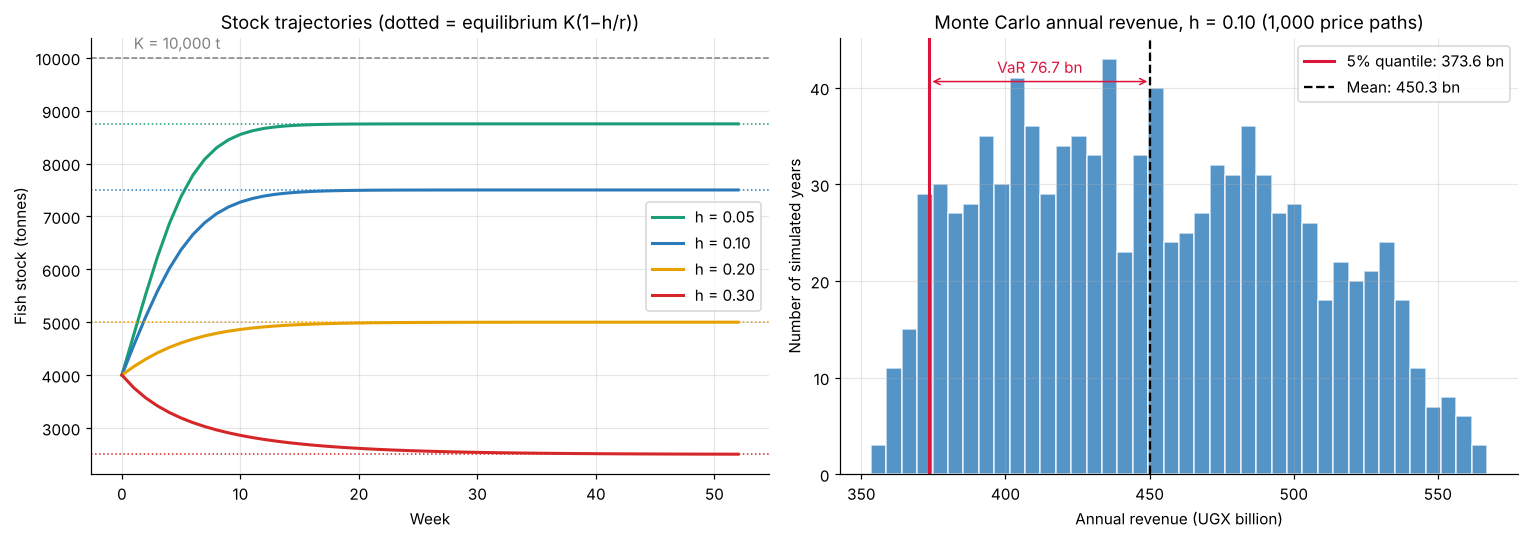

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#1b9e77", "#2a7ab9", "#e6a100", "#d62728"]
for (h, traj), c in zip(trajectories.items(), colors):
    ax1.plot(np.arange(WEEKS + 1), traj, color=c, lw=2, label=f"h = {h:.2f}")
    ax1.axhline(K * max(0, 1 - h / R), color=c, ls=":", lw=1)
ax1.axhline(K, color="grey", ls="--", lw=1); ax1.text(1, K * 1.01, "K = 10,000 t", color="grey", va="bottom")
ax1.set_xlabel("Week"); ax1.set_ylabel("Fish stock (tonnes)")
ax1.set_title("Stock trajectories (dotted = equilibrium K(1−h/r))"); ax1.legend()

ax2.hist(annual / 1e9, bins=40, color="#2a7ab9", alpha=0.8, edgecolor="white")
ax2.axvline(var["quantile"] / 1e9, color="crimson", lw=2, label=f"5% quantile: {var['quantile']/1e9:,.1f} bn")
ax2.axvline(var["mean"] / 1e9, color="k", ls="--", lw=1.5, label=f"Mean: {var['mean']/1e9:,.1f} bn")
ax2.annotate("", xy=(var["quantile"]/1e9, ax2.get_ylim()[1]*0.9), xytext=(var["mean"]/1e9, ax2.get_ylim()[1]*0.9),
             arrowprops=dict(arrowstyle="<->", color="crimson"))
ax2.text((var["quantile"]+var["mean"])/2e9, ax2.get_ylim()[1]*0.92, f"VaR {var['var']/1e9:,.1f} bn",
         ha="center", color="crimson")
ax2.set_xlabel("Annual revenue (UGX billion)"); ax2.set_ylabel("Number of simulated years")
ax2.set_title(f"Monte Carlo annual revenue, h = 0.10 ({N_PATHS:,} price paths)"); ax2.legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "p3_stock_and_var.png", bbox_inches="tight"); plt.show()

## Extension — 8-week closed season over 5 years

Closed season = weeks 12–19 of each year (roughly the March–May long rains, a common breeding peak). Harvest rate
during open weeks is kept at the scenario value. 1,000 price paths over 260 weeks.

In [9]:
YEARS5 = 5 * 52
CLOSED = range(12, 20)
long_prices = PriceModel(seed=SEED + 1).simulate(YEARS5, n_paths=N_PATHS)
ext_rows = []
for h in H_RATES:
    for closed in (False, True):
        s = FishStock(r=R, K=K, N0=N0, h=h, closed_weeks=CLOSED if closed else ())
        N5, H5 = s.simulate(YEARS5)
        rev5 = weekly_revenue(H5, long_prices).sum(axis=1)
        ext_rows.append({"h": h, "closed season": closed, "5-yr catch (t)": H5.sum(),
                         "mean 5-yr revenue (UGX bn)": rev5.mean() / 1e9,
                         "year-5 revenue (UGX bn)": weekly_revenue(H5[-52:], long_prices[:, -52:]).sum(axis=1).mean() / 1e9,
                         "final stock (t)": N5[-1], "min stock (t)": N5.min()})
ext = pd.DataFrame(ext_rows)
pivot = ext.pivot(index="h", columns="closed season", values="mean 5-yr revenue (UGX bn)")
pivot["change %"] = (pivot[True] / pivot[False] - 1) * 100
display(ext.round(2))
display(pivot.round(2))

,h,closed season,5-yr catch (t),mean 5-yr revenue (UGX bn),year-5 revenue (UGX bn),final stock (t),min stock (t)
0,0.050,False,"112,714.610","1,389.630",283.460,"8,750.000","4,000.000"
1,0.050,True,"96,032.670","1,184.470",241.920,"8,750.000","4,000.000"
2,0.100,False,"193,362.510","2,383.870",485.940,"7,500.000","4,000.000"
3,0.100,True,"166,810.450","2,057.360",419.770,"7,500.020","4,000.000"
4,0.200,False,"258,871.700","3,191.150",647.920,"5,000.000","4,000.000"
5,0.200,True,"234,778.120","2,895.160",587.750,"5,001.610","4,000.000"
6,0.300,False,"198,472.160","2,445.190",485.940,"2,500.000","2,500.000"
7,0.300,True,"212,630.010","2,620.760",523.240,"2,554.520","2,515.130"


closed season,False,True,change %
h,,,
0.050,"1,389.630","1,184.470",-14.760
0.100,"2,383.870","2,057.360",-13.700
0.200,"3,191.150","2,895.160",-9.280
0.300,"2,445.190","2,620.760",7.180


## Findings & Limitations

**Sustainability.** With r = 0.4 the logistic model has a clear answer the Fibonacci baseline could never give:
the long-run catch is h·K(1 − h/r), maximised at **h = r/2 = 0.20**, where stock settles at K/2 = 5,000 t and the
weekly catch equals the MSY of rK/4 = 1,000 t. The simulation matches theory almost exactly. Both h = 0.10 and
h = 0.30 deliver the *same* long-run yield (750 t/week, 75 % of MSY), but they are not equivalent: h = 0.10 keeps
7,500 t in the lake, while h = 0.30 holds the stock at 2,500 t, a quarter of capacity, leaving little buffer
against a bad breeding year or a modelling error in r.
The current h = 0.10 is sustainable but conservative.

**Risk.** Revenue variance is ~1.9 × 10¹⁸ UGX², so the old 50,000 threshold flagged every scenario. Using CV, h = 0.10 is Medium risk (CV 0.15) and its 5 % VaR is ~UGX 77 bn, i.e. a 1-in-20 year
earns ~17 % less than average. Note that part of the weekly CV comes from the stock *ramping up* from 4,000 t
(a trend), not from randomness; price alone has CV ≈ 0.09.

**Closed season.** Over five years an 8-week closure *reduces* revenue by 9–15 % when harvesting is at or below
MSY, but *raises* it by 7 % at h = 0.30, because resting an over-fished stock lets it rebuild. A closed season is
a remedy for over-fishing, not a free gain.

**Limitations.** r = 0.4 *per week* is extremely fast (stocks hit equilibrium within weeks), harvest is
deterministic, prices ignore catch volume (a big landing would depress prices), and VaR covers only price risk.
Absolute tonnages and revenues are illustrative.